<a href="https://colab.research.google.com/github/IzadoraGalarza/TP1_G5_IA/blob/main/notebooks/parte2_codificacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Etapa 2 · Parte 2 — Codificação categórica (Samuel Alves)

Este notebook roda sozinho (Colab: **Ambiente de execução → Executar tudo**, cerca de 5 min).

- **Seção A** — preparação e estrutura comum **copiadas do Colab do grupo** (Parte 1, Izadora), só para este arquivo rodar isolado. **Não copiar** para o Colab do grupo.
- **Seção B** — a Parte 2. **É isto que vai para o Colab do grupo**, logo depois da célula que cria `train_clean`.

Resumo dos resultados e da decisão: [`docs/parte2_codificacao.md`](https://github.com/IzadoraGalarza/TP1_G5_IA/blob/main/docs/parte2_codificacao.md).

---
## Seção A — Preparação e estrutura comum (não copiar)

In [1]:
# No Colab, clona o repositório para ter a base; localmente usa a pasta do projeto.
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    if not os.path.exists('/content/TP1_G5_IA'):
        !git clone -q https://github.com/IzadoraGalarza/TP1_G5_IA.git /content/TP1_G5_IA
    %cd /content/TP1_G5_IA

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data'
OUT_DIR = PROJECT_ROOT / 'output' / 'etapa_2'
OUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TARGET_COL = 'class'
df = pd.read_csv(DATA_DIR / 'treino.csv')

In [2]:
# !pip install -q imbalanced-learn
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
                                   RobustScaler, FunctionTransformer)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
TARGET, ID = (TARGET_COL or 'class'), 'id'
TEST_PATH = DATA_DIR / 'teste_sem_rotulo.csv'
train = df.copy() if df is not None else pd.read_csv(DATA_DIR / 'treino.csv')
test  = pd.read_csv(TEST_PATH)
print(train.shape, test.shape)
print('Colunas só no treino:', set(train.columns) - set(test.columns))
print('Colunas só no teste :', set(test.columns) - set(train.columns))

(69833, 50) (24333, 50)
Colunas só no treino: {'class'}
Colunas só no teste : {'id'}


In [3]:
REDUNDANT = ['src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'protocolo_cod',
             'num_outbound_cmds', 'is_host_login']
LEAK_SUSPECTS = ['tipo_alerta_soc', 'tempo_resposta_analista_min', 'score_ids_legado']   # confirmar em 1.1

RANGES = {'count': (0, 511), 'srv_count': (0, 511), 'dst_host_count': (0, 255), 'dst_host_srv_count': (0, 255)}
RATE_COLS = [c for c in train.columns if c.endswith('_rate')]
NONNEG = ['duration', 'src_bytes', 'dst_bytes']

CLEANING = {
    'A_sem_limpeza'     : dict(drop=[],                        norm_cat=False, range_na=False, dedup=False, conflicts='keep'),
    'B_normaliza+faixa' : dict(drop=[],                        norm_cat=True,  range_na=True,  dedup=False, conflicts='keep'),
    'C_B+dedup'         : dict(drop=[],                        norm_cat=True,  range_na=True,  dedup=True,  conflicts='keep'),
    'D_C+sem_conflitos' : dict(drop=[],                        norm_cat=True,  range_na=True,  dedup=True,  conflicts='drop'),
    'E_D+redundantes'   : dict(drop=REDUNDANT,                 norm_cat=True,  range_na=True,  dedup=True,  conflicts='drop'),
    'F_E+leakage'       : dict(drop=REDUNDANT + LEAK_SUSPECTS, norm_cat=True,  range_na=True,  dedup=True,  conflicts='drop'),
}

def normalize_cats(d):
    d = d.copy()
    for c in ['protocol_type', 'service', 'flag']:
        if c in d: d[c] = d[c].astype(object).str.strip().str.lower()   # object (não 'string'): mantém NaN compatível com o imputer
    return d

def mask_out_of_range(d):
    d = d.copy()
    for c, (lo, hi) in RANGES.items():
        if c in d: d.loc[(d[c] < lo) | (d[c] > hi), c] = np.nan
    for c in RATE_COLS:
        if c in d: d.loc[(d[c] < 0) | (d[c] > 1), c] = np.nan
    for c in NONNEG:
        if c in d: d.loc[d[c] < 0, c] = np.nan
    return d

def prepare(d, drop, norm_cat, range_na, **_):
    """Transformações SEM estado (não aprendem nada): aplicar IGUAL no treino e no teste."""
    d = d.drop(columns=[c for c in drop + [ID] if c in d.columns])
    if norm_cat: d = normalize_cats(d)
    if range_na: d = mask_out_of_range(d)
    return d

def clean_train(d, drop, norm_cat, range_na, dedup, conflicts):
    """Remove LINHAS: só no treino, antes do CV."""
    d = prepare(d, drop, norm_cat, range_na)
    feats = [c for c in d.columns if c != TARGET]
    if dedup: d = d.drop_duplicates()
    if conflicts == 'drop':    # mesmas features, classes diferentes = ruído (remove, não relabela)
        d = d[~d.groupby(feats, dropna=False)[TARGET].transform('nunique').gt(1)]
    return d.reset_index(drop=True)

In [4]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = pd.DataFrame(X); self.cols_ = list(X.columns)
        self.maps_ = {c: X[c].value_counts(normalize=True) for c in self.cols_}
        return self
    def transform(self, X):
        X = pd.DataFrame(X, columns=self.cols_)
        return np.column_stack([X[c].map(self.maps_[c]).fillna(0).astype(float).values for c in self.cols_])

ENCODERS = {
    'onehot'   : lambda: OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False),
    'ordinal'  : lambda: OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    'frequency': lambda: FrequencyEncoder(),
}
SCALERS = {
    'standard': lambda: StandardScaler(),
    'minmax'  : lambda: MinMaxScaler(),
    'robust'  : lambda: RobustScaler(),
    'log'     : lambda: SkPipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('sc', StandardScaler())]),
    'nenhum'  : lambda: 'passthrough',
}
BALANCERS = {                       # n_cat = nº de colunas categóricas (ficam nas primeiras posições)
    'nenhum' : lambda n_cat: None,
    'RUS'    : lambda n_cat: RandomUnderSampler(random_state=SEED),
    'SMOTE'  : lambda n_cat: SMOTE(random_state=SEED),
    'SMOTENC': lambda n_cat: SMOTENC(categorical_features=list(range(n_cat)), random_state=SEED),
}
MODELS = {
    'DT': lambda: DecisionTreeClassifier(random_state=SEED),
    'RF': lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'LR': lambda: LogisticRegression(max_iter=1000),
}

def make_preprocessor(X, encoder='onehot', scaler='standard'):
    cat = X.select_dtypes(exclude='number').columns.tolist()     # protocol_type, service, flag (+ tipo_alerta_soc se não removido)
    num = X.select_dtypes('number').columns.tolist()
    cat_pipe = SkPipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', ENCODERS[encoder]())])
    num_pipe = SkPipeline([('imp', SimpleImputer(strategy='median')), ('sc', SCALERS[scaler]())])
    return ColumnTransformer([('cat', cat_pipe, cat), ('num', num_pipe, num)]), len(cat)   # categóricas primeiro

def build_pipeline(X, balancer='nenhum', model='RF', encoder='onehot', scaler='standard', reducer=None):
    if balancer == 'SMOTENC' and encoder != 'ordinal':
        raise ValueError("SMOTENC exige encoder='ordinal' (precisa das colunas categóricas como códigos).")
    prep, n_cat = make_preprocessor(X, encoder, scaler)
    steps = [('prep', prep)]
    if reducer is not None: steps.append(('red', reducer))     # com reducer, a ordem das colunas muda: não usar com SMOTENC
    bal = BALANCERS[balancer](n_cat)
    if bal is not None: steps.append(('bal', bal))             # imblearn só aplica no fit (treino do fold)
    steps.append(('clf', MODELS[model]()))
    return Pipeline(steps)

CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'f1_macro': 'f1_macro', 'precision_macro': 'precision_macro', 'recall_macro': 'recall_macro', 'accuracy': 'accuracy'}
def signature_groups(X):
    return pd.util.hash_pandas_object(X.astype(str), index=False).values

RESULTS = []
def run_experiment(df_clean, cleaning, balancer='nenhum', model='RF', encoder='onehot', scaler='standard', reducer=None, tag=''):
    X = df_clean.drop(columns=[TARGET]); y = (df_clean[TARGET].astype(str).str.strip().str.lower() != 'normal').astype(int)
    pipe = build_pipeline(X, balancer, model, encoder, scaler, reducer)
    r = cross_validate(pipe, X, y, cv=CV, groups=signature_groups(X), scoring=SCORING, n_jobs=-1)
    row = dict(limpeza=cleaning, codificacao=encoder, normalizacao=scaler, balanceamento=balancer,
               reducao=tag or ('nenhuma' if reducer is None else type(reducer).__name__), modelo=model, n_linhas=len(df_clean))
    for k in SCORING: row[k] = r[f'test_{k}'].mean(); row[k + '_std'] = r[f'test_{k}'].std()
    RESULTS.append(row); return row

def export_results(path):
    pd.DataFrame(RESULTS).to_csv(path, index=False); print('salvo em', path, f'({len(RESULTS)} linhas)')

In [5]:
CLEAN_NAME = 'F_E+leakage'
CLEAN_CFG  = CLEANING[CLEAN_NAME]
train_clean = clean_train(train, **CLEAN_CFG)
print(CLEAN_NAME, train_clean.shape)

F_E+leakage (55063, 40)


---
## Seção B — Parte 2 (copiar daqui até o fim para o Colab do grupo)

## Parte 2 – Codificação simbólico-numérica e ausentes categóricos · _responsável: Samuel Alves_
Compara como transformar `protocol_type`, `service` e `flag` em números, mantendo **fixos** a limpeza (`F_E+leakage`), a escala (`standard`), o balanceamento (`nenhum`) e o modelo. Variantes:

| Variante | O que muda |
|---|---|
| `onehot_puro` | uma coluna por categoria, sem agrupar nada |
| `onehot` (padrão da estrutura comum) | one-hot com categorias raras (< 20 linhas) agrupadas em "infrequente" |
| `ordinal` | um inteiro por categoria (ordem alfabética, arbitrária) |
| `frequency` | frequência relativa da categoria no treino do fold |
| `onehot` + `ausente` | igual ao `onehot`, mas o valor faltante vira a categoria explícita `ausente` em vez da moda |

Tudo que aprende algo (vocabulário, frequências, moda, categorias raras) é ajustado dentro do Pipeline, só no treino de cada fold. Rodamos com **RF** (modelo padrão da equipe) e **LR** (sensível a como a categoria vira número).

In [6]:
from pathlib import Path
OUT_DIR = Path(globals().get('OUT_DIR', '.'))

# 2.1 Diagnóstico dos atributos categóricos (após a limpeza escolhida)
CAT_COLS = [c for c in ['protocol_type', 'service', 'flag'] if c in train_clean.columns]
y_p2 = train_clean[TARGET].astype(str).str.strip().str.lower()

diag = pd.DataFrame({
    'níveis': train_clean[CAT_COLS].nunique(),
    'ausentes': train_clean[CAT_COLS].isna().sum(),
    'ausentes_%': (train_clean[CAT_COLS].isna().mean() * 100).round(2),
    'níveis_<20_linhas': [int((train_clean[c].value_counts() < 20).sum()) for c in CAT_COLS],
})
display(diag)

print('Ausência por classe (%):')
display((train_clean[CAT_COLS].isna().groupby(y_p2).mean() * 100).round(2))

serv = pd.crosstab(train_clean['service'], y_p2)
serv['total'] = serv.sum(axis=1)
serv['%_anomaly'] = (serv['anomaly'] / serv['total'] * 100).round(1)
display(serv.sort_values('total', ascending=False).head(15))

# Por que normalizar antes: espaços no fim criam categorias falsas em service
bruto = train['service'].dropna().astype(str)
print(f"service: {bruto.nunique()} níveis brutos -> {bruto.str.lower().nunique()} com lower -> "
      f"{bruto.str.strip().str.lower().nunique()} com strip+lower")

,níveis,ausentes,ausentes_%,níveis_<20_linhas
protocol_type,3,0,0.00,0
service,65,3493,6.34,42
flag,11,3225,5.86,3


Ausência por classe (%):


,protocol_type,service,flag
class,,,
anomaly,0.0,6.77,6.44
normal,0.0,6.33,5.84


class,anomaly,normal,total,%_anomaly
service,,,,
http,108,29178,29286,0.4
domain_u,1,6272,6273,0.0
smtp,12,4922,4934,0.2
ftp_data,44,3380,3424,1.3
private,607,1152,1759,34.5
other,62,1679,1741,3.6
ftp,26,830,856,3.0
telnet,72,600,672,10.7
finger,32,406,438,7.3


service: 96 níveis brutos -> 96 com lower -> 67 com strip+lower


,codificacao,colunas_categoricas,colunas_totais
0,onehot_puro,79,115
1,onehot,36,72
2,ordinal,3,39
3,frequency,3,39


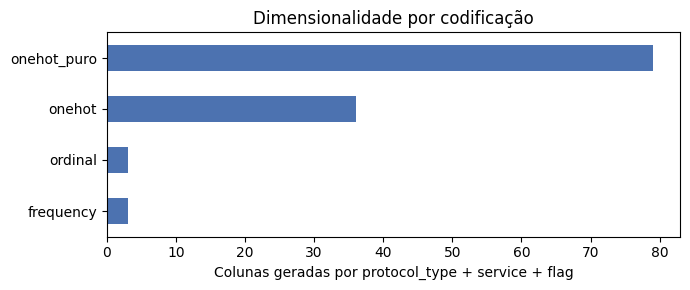

In [7]:
# 2.2 Dimensionalidade gerada por cada codificação
ENCODERS['onehot_puro'] = lambda: OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_p2 = train_clean.drop(columns=[TARGET])
dims = []
for enc in ['onehot_puro', 'onehot', 'ordinal', 'frequency']:
    prep, n_cat = make_preprocessor(X_p2, encoder=enc)
    Xt = prep.fit_transform(X_p2)          # só descritivo: conta colunas, não avalia nada
    n_num = len(X_p2.select_dtypes('number').columns)
    dims.append({'codificacao': enc, 'colunas_categoricas': Xt.shape[1] - n_num, 'colunas_totais': Xt.shape[1]})
dims = pd.DataFrame(dims)
display(dims)

ax = dims.plot.barh(x='codificacao', y='colunas_categoricas', legend=False, figsize=(7, 3), color='#4C72B0')
ax.set(xlabel='Colunas geradas por protocol_type + service + flag', ylabel='', title='Dimensionalidade por codificação')
ax.invert_yaxis(); plt.tight_layout(); plt.savefig(OUT_DIR / 'parte2_dimensionalidade.png', dpi=150); plt.show()

In [8]:
# 2.3 Comparação por validação cruzada (mesma estrutura comum da Parte 1)
inicio_p2 = len(RESULTS)

for model in ['RF', 'LR']:
    for enc in ['onehot_puro', 'onehot', 'ordinal', 'frequency']:
        run_experiment(train_clean, CLEAN_NAME, encoder=enc, model=model)

    # Imputação: categoria explícita 'ausente' em vez da moda. fillna com constante não aprende nada
    # dos dados, então pode ser feito antes do CV sem vazamento.
    train_ausente = train_clean.copy()
    train_ausente[CAT_COLS] = train_ausente[CAT_COLS].fillna('ausente')
    run_experiment(train_ausente, CLEAN_NAME, encoder='onehot', model=model, tag='imput_ausente')

res_p2 = pd.DataFrame(RESULTS[inicio_p2:])
res_p2['imputacao_cat'] = np.where(res_p2['reducao'] == 'imput_ausente', 'ausente', 'moda')
res_p2['reducao'] = 'nenhuma'
res_p2 = res_p2.merge(dims[['codificacao', 'colunas_categoricas']], on='codificacao', how='left')
res_p2.to_csv(OUT_DIR / 'resultados_parte2_codificacao.csv', index=False)

cols = ['modelo', 'codificacao', 'imputacao_cat', 'colunas_categoricas', 'f1_macro', 'f1_macro_std', 'precision_macro', 'recall_macro']
res_p2.sort_values(['modelo', 'f1_macro'], ascending=[True, False])[cols].round(4)

,modelo,codificacao,imputacao_cat,colunas_categoricas,f1_macro,f1_macro_std,precision_macro,recall_macro
9,LR,onehot,ausente,36,0.9340,0.0093,0.9737,0.9010
6,LR,onehot,moda,36,0.9317,0.0036,0.9717,0.8983
5,LR,onehot_puro,moda,79,0.9309,0.0041,0.9707,0.8977
7,LR,ordinal,moda,3,0.9075,0.0040,0.9594,0.8667
8,LR,frequency,moda,3,0.9006,0.0045,0.9633,0.8537
1,RF,onehot,moda,36,0.9765,0.0035,0.9936,0.9606
4,RF,onehot,ausente,36,0.9763,0.0029,0.9941,0.9598
2,RF,ordinal,moda,3,0.9753,0.0047,0.9918,0.9600
3,RF,frequency,moda,3,0.9749,0.0035,0.9932,0.9581
0,RF,onehot_puro,moda,79,0.9740,0.0042,0.9929,0.9567


In [9]:
# 2.4 Regra de decisão (fixada antes de ver os resultados): no modelo da equipe (RF), entre as
# variantes a até 1 desvio-padrão do melhor F1-macro, escolher a de menos colunas.
rf = res_p2[res_p2['modelo'] == 'RF'].sort_values('f1_macro', ascending=False)
melhor = rf.iloc[0]
candidatas = rf[rf['f1_macro'] >= melhor['f1_macro'] - melhor['f1_macro_std']]
escolhida = candidatas.sort_values(['colunas_categoricas', 'f1_macro'], ascending=[True, False]).iloc[0]
print(f"Melhor F1-macro (RF): {melhor['codificacao']} / {melhor['imputacao_cat']} = {melhor['f1_macro']:.4f} ± {melhor['f1_macro_std']:.4f}")
print(f"Escolhida pela regra: {escolhida['codificacao']} / imputação {escolhida['imputacao_cat']}")

Melhor F1-macro (RF): onehot / moda = 0.9765 ± 0.0035
Escolhida pela regra: ordinal / imputação moda


### 2.5 Justificativa

**Diagnóstico.** Após `strip` + `lower`, `service` tem 65 níveis no treino limpo (eram 96 brutos: 29 eram o mesmo serviço com espaço no final, como `'http '`), `flag` tem 11 e `protocol_type` 3. `service` é muito concentrado: 42 níveis têm menos de 20 linhas, e alguns raros são muito informativos (`private`: 34,5% de anomalias; `ecr_i`: 32,7%; `eco_i`: 25,2%, contra 0,4% em `http`). `service` e `flag` têm cerca de 6% de ausentes, com taxa quase igual nas duas classes (6,8% × 6,3% em `service`).

**Resultados.**
- **RF:** todas as codificações empatam (F1-macro de 0,974 a 0,977, diferenças menores que 1 desvio-padrão). Árvores separam categorias por limiares, então a ordem artificial do ordinal e a perda de identidade da frequência quase não atrapalham.
- **LR:** o one-hot fica claramente acima (0,932 × 0,908 do ordinal e 0,901 da frequência). Um modelo linear dá um único peso ao código numérico, então não consegue isolar serviços raros e suspeitos como `private`, `ecr_i` e `eco_i`; o ordinal ainda impõe uma ordem alfabética sem significado.
- **Alta cardinalidade:** agrupar as categorias com menos de 20 linhas (`onehot` padrão) reduz as colunas de 79 para 36 sem perda de desempenho, nos dois modelos, em relação ao one-hot puro.
- **Imputação:** a categoria `ausente` não muda o resultado em relação à moda (diferença menor que 1 desvio-padrão), o que bate com a ausência quase igual entre as classes.
- **Vazamento:** nenhuma técnica usa o rótulo (por isso não usamos *target encoding*); vocabulário, frequências, moda e categorias raras são aprendidos só no treino de cada fold.

**Decisão.** Pela regra fixada antes de ver os resultados, com o RF (modelo da equipe) a escolha é **`ordinal` com imputação pela moda**: mesmo desempenho com 3 colunas em vez de 36 ou 79. Ela também é a codificação que o `SMOTENC` da Parte 4 exige. Para modelos lineares ou baseados em distância (LR, KNN, redes), usar **`onehot` com raras agrupadas**.